# 05 · Error analysis: where and why does the model fail on the external data?

For each selected architecture, the E1 and E2 runs with the lowest A-validation loss are analysed (selection again uses A only).

1. Confusion matrices at the frozen threshold
2. Threshold transfer: what the A-chosen threshold does on B, compared with a B-optimal threshold (oracle, analysis only, never used for reporting)
3. Calibration (reliability, ECE)
4. Score distributions by class, including B's "not normal" studies
5. B subgroups: view position (AP/PA), sex, age (including the pediatric part of B)
6. Shortcut probe: do Test A scores still track acquisition properties (image width, file size) within a class?
7. Grad-CAM: what drives confident errors?

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "reports/results"; RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

import torch
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
from scipy.stats import spearmanr
from cxr.analysis import collect_runs, ece, EVAL_LABELS
from cxr.metrics import all_metrics, bootstrap_ci, choose_threshold
from cxr.data import ensure_cache, read_manifest
from cxr.engine import load_model, get_device
from cxr.explain import gradcam, overlay

runs = collect_runs()
sel = json.loads((ROOT / "configs/selected_archs.json").read_text())["selected"]
A_MAN, B_MAN = ROOT / "artifacts/manifests/kermany.csv", ROOT / "artifacts/manifests/rsna.csv"
def best_seed(exp, arch):
    r = runs[(runs.experiment == exp) & (runs.arch == arch)].drop_duplicates("seed")
    return int(r.sort_values("best_val_loss").seed.iloc[0]) if len(r) else None
MODELS = {(e, a): best_seed(e, a) for a in sel for e in ["E1", "E2"] if best_seed(e, a) is not None}
def run_path(e, a, s): return ROOT / f"artifacts/runs/{e}/{a}/seed{s}"
def preds(e, a, s, name): return pd.read_csv(run_path(e, a, s) / f"preds_{name}.csv", dtype={"patient_id": str})
def thr_of(e, a, s): return json.loads((run_path(e, a, s) / "run.json").read_text())["threshold"]
print(MODELS)

{('E1', 'efficientnet_b0'): 0, ('E2', 'efficientnet_b0'): 1, ('E1', 'vit_small'): 0, ('E2', 'vit_small'): 0}


/home/edelweizse/Projects/uni/AIE/final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1–2. Confusion matrices and threshold transfer

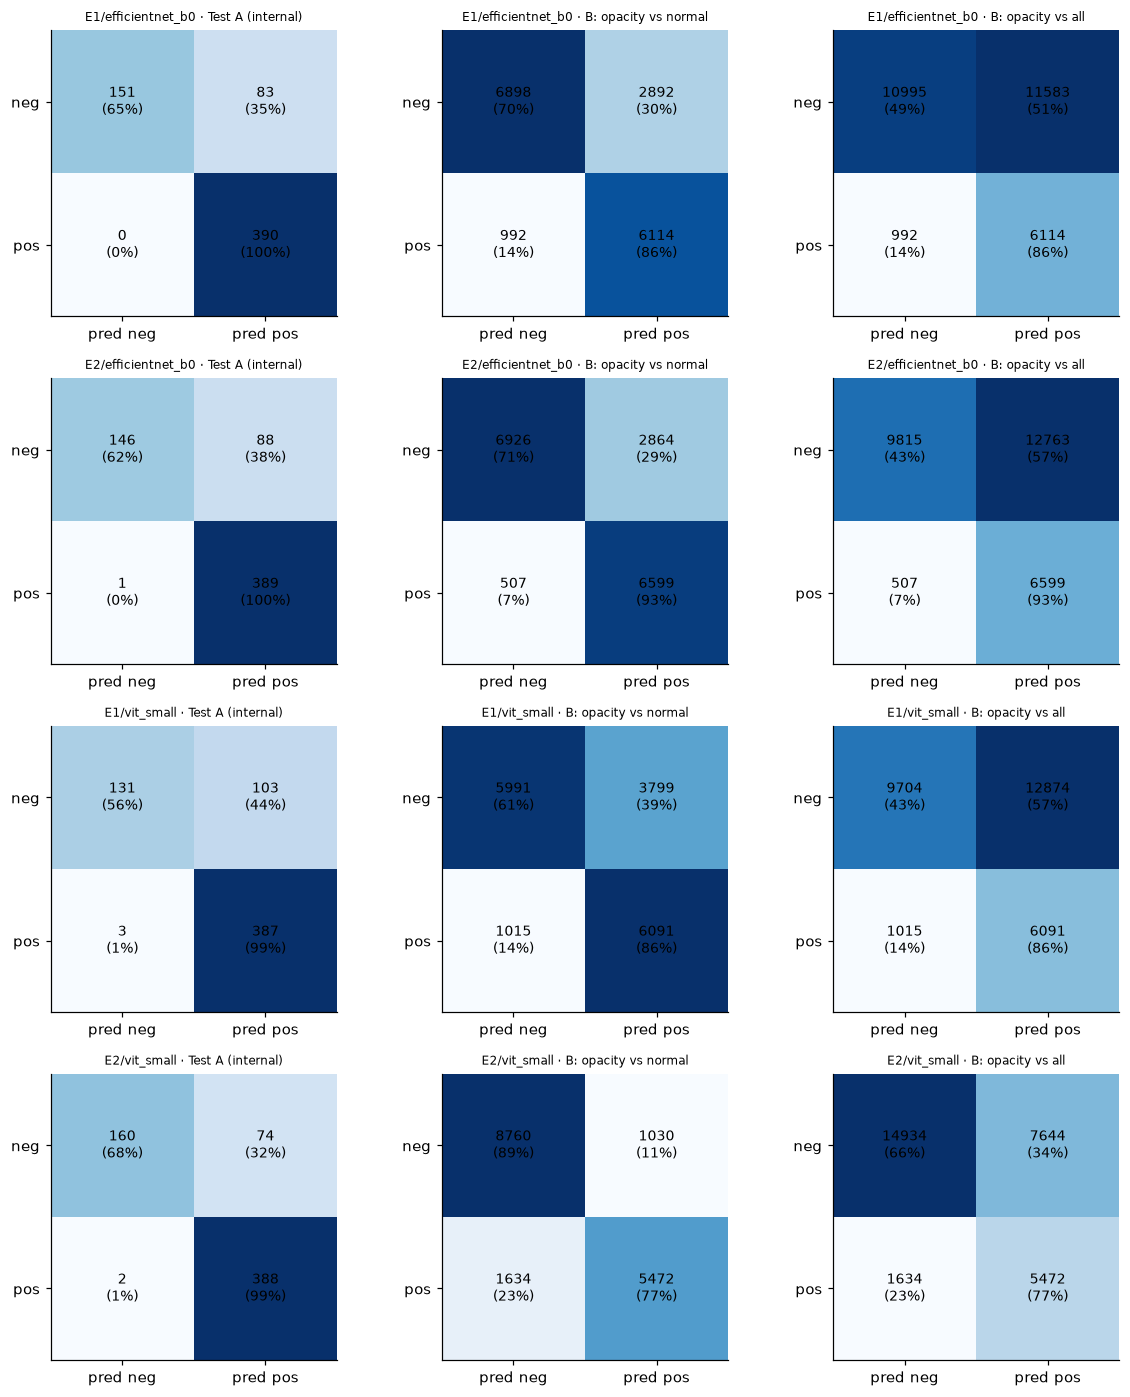

,model,eval,auroc,thr_A_val,sens@A-thr,spec@A-thr,thr_oracle(B),sens@oracle,spec@oracle
0,E1/efficientnet_b0/seed0,Test A (internal),0.935,0.914,1.000,0.645,0.993,0.951,0.863
1,E1/efficientnet_b0/seed0,B: opacity vs normal,0.855,0.914,0.860,0.705,0.955,0.815,0.758
2,E1/efficientnet_b0/seed0,B: opacity vs all,0.735,0.914,0.860,0.487,0.969,0.775,0.596
3,E2/efficientnet_b0/seed1,Test A (internal),0.895,0.498,0.997,0.624,0.987,0.979,0.808
4,E2/efficientnet_b0/seed1,B: opacity vs normal,0.904,0.498,0.929,0.707,0.964,0.854,0.839
5,E2/efficientnet_b0/seed1,B: opacity vs all,0.761,0.498,0.929,0.435,0.987,0.785,0.656
6,E1/vit_small/seed0,Test A (internal),0.800,0.918,0.992,0.560,0.979,0.969,0.684
7,E1/vit_small/seed0,B: opacity vs normal,0.809,0.918,0.857,0.612,0.973,0.763,0.749
8,E1/vit_small/seed0,B: opacity vs all,0.698,0.918,0.857,0.430,0.975,0.740,0.586
9,E2/vit_small/seed0,Test A (internal),0.896,0.733,0.995,0.684,0.978,0.990,0.791


In [2]:
rows = []
fig, axes = plt.subplots(len(MODELS), 3, figsize=(11, 3.2 * len(MODELS)), squeeze=False)
for i, ((e, a), s) in enumerate(MODELS.items()):
    thr = thr_of(e, a, s)
    for j, key in enumerate(EVAL_LABELS):
        name, col = key.split(":")
        df = preds(e, a, s, name); df = df[df[col].notna()]
        y, p = df[col].astype(int).to_numpy(), df.prob.to_numpy()
        cm = confusion_matrix(y, p >= thr, labels=[0, 1])
        ax = axes[i, j]; ax.imshow(cm, cmap="Blues"); ax.grid(False)
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, f"{v}\n({v / cm[r].sum():.0%})", ha="center", va="center", fontsize=9)
        ax.set_xticks([0, 1], ["pred neg", "pred pos"]); ax.set_yticks([0, 1], ["neg", "pos"])
        ax.set_title(f"{e}/{a} · {EVAL_LABELS[key]}", fontsize=8)
        oracle = choose_threshold(y, p, "youden")
        m_frozen, m_oracle = all_metrics(y, p, thr), all_metrics(y, p, oracle)
        rows.append({"model": f"{e}/{a}/seed{s}", "eval": EVAL_LABELS[key], "auroc": m_frozen["auroc"],
                     "thr_A_val": thr, "sens@A-thr": m_frozen["sensitivity"], "spec@A-thr": m_frozen["specificity"],
                     "thr_oracle(B)": oracle, "sens@oracle": m_oracle["sensitivity"], "spec@oracle": m_oracle["specificity"]})
plt.tight_layout(); plt.savefig(FIG / "confusion_matrices.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(rows).round(3))

The oracle columns use B's own labels to pick a threshold. They are *not* a valid performance estimate. They show how much of the external error is a shifted operating point (a recalibration problem that local threshold tuning could fix) and how much is lost ranking ability (AUROC).

**Insights (threshold transfer)**
* The thresholds chosen on A-validation range from 0.50 to 0.92 across these four models. A-validation is nearly perfectly separable, so Youden's J is satisfied by many thresholds and the choice is somewhat arbitrary.
* For three of the four models the *B-optimal* (oracle) threshold is very high (0.95–0.97). These models give most B images high scores, positives and negatives alike. At the A threshold this shows up as decent sensitivity (0.86–0.93) with poor specificity (0.61–0.71). With the oracle threshold, sensitivity and specificity become more balanced (e.g. E1 EfficientNet: 0.82 / 0.76).
* E2 ViT is the exception: its oracle threshold is low (0.26), because it scores B images *lower* overall. The direction of miscalibration is model-specific, so no fixed correction would work.
* Takeaway: a large part of the frozen-threshold error on B is operating-point shift, which local recalibration on a small labelled sample from the new hospital could fix. The rest is lost discrimination (AUROC), which recalibration cannot fix.

## 3. Calibration
A model is **calibrated** if, among images scored 0.8, about 80% are truly positive. The reliability diagram plots the mean score per bin (x) against the observed positive rate (y); the diagonal is perfect calibration. **ECE** (expected calibration error) is the bin-weighted average distance from the diagonal: 0 is perfect, and 0.1 means scores are off by about 10 percentage points on average.

Calibration matters clinically (a score is read as a risk), and it is *not* preserved under domain shift: even a model that ranks B well (good AUROC) can be systematically over-confident there. Label smoothing and early stopping on BCE help calibration in-domain only.

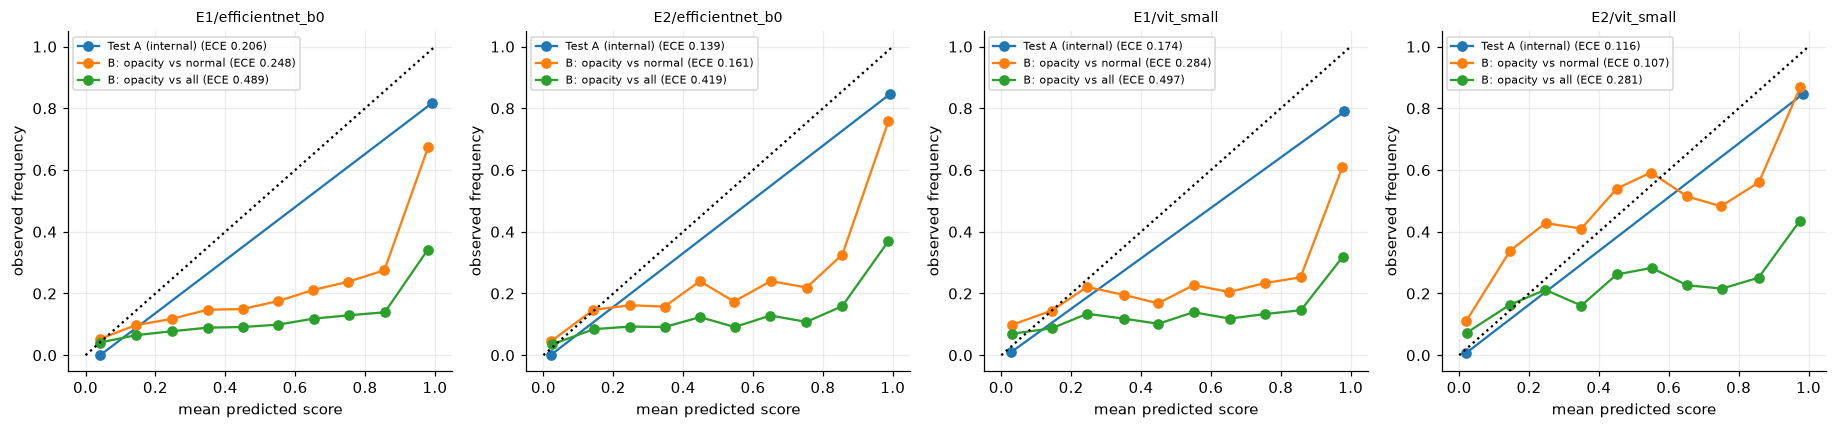

,model,eval,ece,mean_score,prevalence
0,E1/efficientnet_b0,Test A (internal),0.206,0.831,0.625
1,E1/efficientnet_b0,B: opacity vs normal,0.248,0.664,0.421
2,E1/efficientnet_b0,B: opacity vs all,0.489,0.728,0.239
3,E2/efficientnet_b0,Test A (internal),0.139,0.764,0.625
4,E2/efficientnet_b0,B: opacity vs normal,0.161,0.565,0.421
5,E2/efficientnet_b0,B: opacity vs all,0.419,0.652,0.239
6,E1/vit_small,Test A (internal),0.174,0.799,0.625
7,E1/vit_small,B: opacity vs normal,0.284,0.671,0.421
8,E1/vit_small,B: opacity vs all,0.497,0.721,0.239
9,E2/vit_small,Test A (internal),0.116,0.741,0.625


In [3]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 4), squeeze=False)
cal_rows = []
for ax, ((e, a), s) in zip(axes[0], MODELS.items()):
    for key in EVAL_LABELS:
        name, col = key.split(":")
        df = preds(e, a, s, name); df = df[df[col].notna()]
        y, p = df[col].astype(int).to_numpy(), df.prob.to_numpy()
        bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(p, bins) - 1, 0, 9)
        mp = [p[idx == k].mean() for k in range(10) if (idx == k).sum() >= 20]
        fy = [y[idx == k].mean() for k in range(10) if (idx == k).sum() >= 20]
        ax.plot(mp, fy, "o-", label=f"{EVAL_LABELS[key]} (ECE {ece(y, p):.3f})")
        cal_rows.append({"model": f"{e}/{a}", "eval": EVAL_LABELS[key], "ece": ece(y, p), "mean_score": p.mean(), "prevalence": y.mean()})
    ax.plot([0, 1], [0, 1], "k:"); ax.set_title(f"{e}/{a}", fontsize=9); ax.set_xlabel("mean predicted score"); ax.set_ylabel("observed frequency")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "calibration.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(cal_rows).round(3))

**Insights (calibration)**
* All models are mis-calibrated, even in-domain (Test A ECE 0.12–0.21), mostly towards over-predicting pneumonia: the mean score exceeds prevalence.
* On B (opacity vs normal), E1 models are badly over-confident (ECE 0.25–0.28; mean score 0.66–0.67 vs prevalence 0.42).
* **Augmentation improves calibration substantially:** EfficientNet B ECE 0.248 → 0.161, ViT 0.284 → 0.107. This fits the idea that augmentation reduces reliance on brittle cues that produce extreme scores.
* On the secondary task (including "not normal"), ECE is 0.28–0.50: the models are confidently wrong about abnormal-but-not-pneumonia images.

## 4. Score distributions by class
Ideal: negatives piled near 0, positives near 1, little overlap. Watch two things on B. Where does the "Normal" mass sit compared with A's normals (a shift right means B's normals look abnormal to the model)? And where do the "No Lung Opacity / Not Normal" studies fall (other pathologies, devices and so on, which A never contained)?

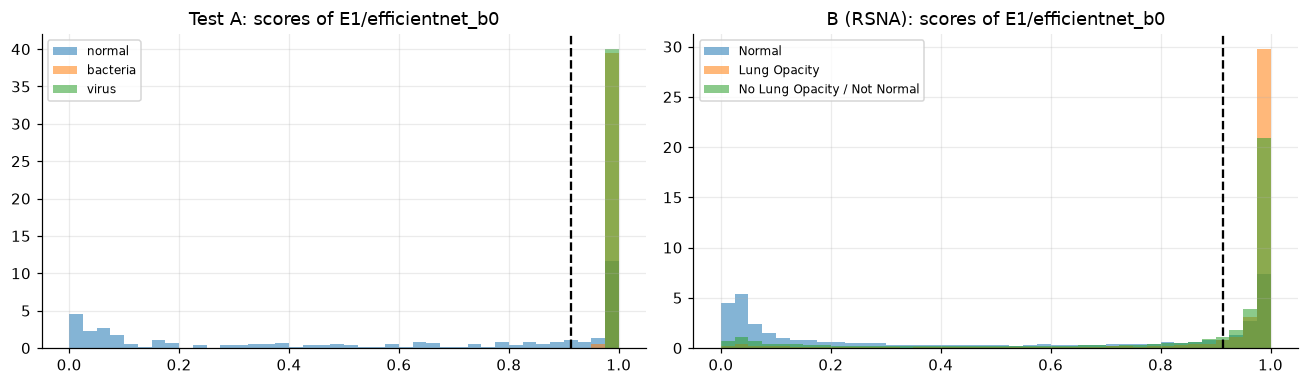

,count,mean,std,min,25%,50%,75%,max
class3,,,,,,,,
Lung Opacity,7106.0,0.919,0.204,0.009,0.974,0.989,0.993,0.998
No Lung Opacity / Not Normal,12788.0,0.814,0.306,0.008,0.813,0.978,0.991,0.998
Normal,9790.0,0.478,0.407,0.007,0.051,0.395,0.951,0.997


In [4]:
e, a = next(iter(MODELS)); s = MODELS[(e, a)]
pa, pb = preds(e, a, s, "A_test"), preds(e, a, s, "B_external")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.linspace(0, 1, 41)
for lab in ["normal", "bacteria", "virus"]:
    axes[0].hist(pa.prob[pa.orig_label == lab], bins=bins, alpha=0.55, density=True, label=lab)
for lab in ["Normal", "Lung Opacity", "No Lung Opacity / Not Normal"]:
    axes[1].hist(pb.prob[pb.class3 == lab], bins=bins, alpha=0.55, density=True, label=lab)
for ax, t in zip(axes, ["Test A", "B (RSNA)"]):
    ax.axvline(thr_of(e, a, s), color="k", ls="--"); ax.set_title(f"{t}: scores of {e}/{a}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "score_distributions.png", bbox_inches="tight"); plt.show()
display(pb.groupby("class3").prob.describe().round(3))

**Insights (score distributions, E1 EfficientNet-B0)**
* B "Normal" studies are *bimodal*: median score 0.40, but more than 25% score above 0.95. A sizeable group of normal adult radiographs looks maximally "pneumonia" to the model. The subgroup analysis below shows these are mostly AP films.
* "No Lung Opacity / Not Normal" studies have a median score of 0.98, essentially treated as pneumonia. The model has learned "abnormal vs normal child", not "pneumonia vs everything else".
* In Test A, bacterial and viral pneumonia are *both* scored ≈0.99 (median 0.996): the model has no difficulty with either subtype. Essentially all Test A errors are **normal children scored high**. E1 normals have a median score of 0.65, so more than half of the healthy children land above 0.5. Augmentation pulls them down (E2 median 0.06), which is where E2's specificity gain comes from.

## 5. B subgroups: who is the model failing?
AUROC within each subgroup, with a 95% bootstrap CI, plus sensitivity and specificity at the frozen threshold. Subgroup AUROC can be *lower* than the pooled AUROC even when every subgroup is similar (Simpson-type effect), because the pooled number also rewards separating subgroups that differ in prevalence. View is the prime example.

In [5]:
def subgroup_table(e, a, s):
    df = preds(e, a, s, "B_external"); thr = thr_of(e, a, s)
    df["age"] = df.age.where(df.age.between(0, 100))          # a few RSNA ages are invalid (e.g. 412)
    df["age_band"] = pd.cut(df.age, [0, 17, 40, 60, 100], labels=["<18", "18-40", "41-60", ">60"])
    df = df[df.label.notna()]
    out = []
    for col in ["view", "sex", "age_band"]:
        for val, g in df.groupby(col, observed=True):
            if g.label.nunique() < 2 or len(g) < 50: continue
            y, p = g.label.astype(int).to_numpy(), g.prob.to_numpy()
            m = all_metrics(y, p, thr); ci = bootstrap_ci(y, p, thr, n_boot=500, keys=("auroc",))["auroc"]
            out.append({"subgroup": f"{col}={val}", "n": len(g), "prevalence": y.mean(), "auroc": m["auroc"],
                        "auroc_ci": f"[{ci[0]:.3f}, {ci[1]:.3f}]", "sensitivity": m["sensitivity"], "specificity": m["specificity"]})
    return pd.DataFrame(out)

for (e, a), s in MODELS.items():
    display(Markdown(f"**{e}/{a}** (seed {s})"))
    t = subgroup_table(e, a, s); display(t.round(3)); t.to_csv(RES / f"b_subgroups_{e}_{a}.csv", index=False)
b_man = read_manifest(B_MAN)
display(pd.crosstab(b_man.class3, b_man.view, normalize="columns").round(3).rename_axis("class share by view"))

**E1/efficientnet_b0** (seed 0)

,subgroup,n,prevalence,auroc,auroc_ci,sensitivity,specificity
0,view=AP,7287,0.754,0.704,"[0.690, 0.718]",0.952,0.238
1,view=PA,9609,0.168,0.761,"[0.748, 0.773]",0.549,0.809
2,sex=F,7242,0.407,0.869,"[0.862, 0.878]",0.859,0.738
3,sex=M,9654,0.431,0.845,"[0.836, 0.853]",0.862,0.679
4,age_band=<18,982,0.484,0.815,"[0.785, 0.841]",0.676,0.797
5,age_band=18-40,5444,0.413,0.872,"[0.862, 0.880]",0.841,0.767
6,age_band=41-60,7209,0.402,0.865,"[0.857, 0.873]",0.885,0.687
7,age_band=>60,3257,0.457,0.840,"[0.825, 0.852]",0.900,0.607


**E2/efficientnet_b0** (seed 1)

,subgroup,n,prevalence,auroc,auroc_ci,sensitivity,specificity
0,view=AP,7287,0.754,0.762,"[0.748, 0.777]",0.989,0.207
1,view=PA,9609,0.168,0.853,"[0.842, 0.863]",0.724,0.820
2,sex=F,7242,0.407,0.905,"[0.898, 0.913]",0.928,0.697
3,sex=M,9654,0.431,0.903,"[0.896, 0.909]",0.929,0.715
4,age_band=<18,982,0.484,0.831,"[0.804, 0.856]",0.914,0.606
5,age_band=18-40,5444,0.413,0.916,"[0.907, 0.923]",0.917,0.772
6,age_band=41-60,7209,0.402,0.909,"[0.902, 0.916]",0.929,0.715
7,age_band=>60,3257,0.457,0.892,"[0.880, 0.902]",0.950,0.601


**E1/vit_small** (seed 0)

,subgroup,n,prevalence,auroc,auroc_ci,sensitivity,specificity
0,view=AP,7287,0.754,0.635,"[0.620, 0.651]",0.925,0.242
1,view=PA,9609,0.168,0.713,"[0.699, 0.728]",0.625,0.695
2,sex=F,7242,0.407,0.829,"[0.820, 0.839]",0.807,0.736
3,sex=M,9654,0.431,0.797,"[0.788, 0.805]",0.893,0.515
4,age_band=<18,982,0.484,0.797,"[0.769, 0.823]",0.739,0.728
5,age_band=18-40,5444,0.413,0.822,"[0.809, 0.833]",0.828,0.680
6,age_band=41-60,7209,0.402,0.817,"[0.807, 0.826]",0.878,0.591
7,age_band=>60,3257,0.457,0.785,"[0.770, 0.801]",0.899,0.507


**E2/vit_small** (seed 0)

,subgroup,n,prevalence,auroc,auroc_ci,sensitivity,specificity
0,view=AP,7287,0.754,0.844,"[0.833, 0.854]",0.890,0.604
1,view=PA,9609,0.168,0.798,"[0.784, 0.811]",0.361,0.960
2,sex=F,7242,0.407,0.904,"[0.897, 0.911]",0.724,0.927
3,sex=M,9654,0.431,0.907,"[0.900, 0.913]",0.803,0.870
4,age_band=<18,982,0.484,0.855,"[0.829, 0.878]",0.537,0.925
5,age_band=18-40,5444,0.413,0.905,"[0.896, 0.914]",0.751,0.916
6,age_band=41-60,7209,0.402,0.915,"[0.908, 0.921]",0.796,0.893
7,age_band=>60,3257,0.457,0.907,"[0.896, 0.916]",0.824,0.852


view,AP,PA
class share by view,,
Lung Opacity,0.405,0.100
No Lung Opacity / Not Normal,0.462,0.404
Normal,0.132,0.496


View position is a well-known confounder in RSNA/NIH data. AP films are typically taken of sicker, often supine patients and carry a higher opacity prevalence, so performance within each view is the fairer measure. The pediatric slice of B (<18 y) is the part of the external data closest to A's population.

**Insights (subgroups)**
* **AP films are the main failure mode.** Within AP, AUROC is only 0.64–0.76 for E1, and specificity at the frozen threshold is about 0.24 (E1 EfficientNet and ViT): about 3 of 4 *normal* AP films are flagged as pneumonia. AP films (portable, supine, magnified heart, overlapping devices) look unlike anything in A's normals. E2 ViT raises AP specificity to 0.60 and AP AUROC to 0.84.
* **Sex:** small differences (F slightly better for E1, ≈0.02–0.03 AUROC); essentially none after augmentation.
* **Age:** surprisingly, the *pediatric* part of B (<18 y, n = 982) is **not** easier. E1 EfficientNet reaches 0.815 there vs 0.86–0.87 for adults 18–60, and its sensitivity is lowest there (0.68). Age match alone does not transfer, presumably because B's children are mostly adolescents imaged with adult protocols at a different hospital, and the label definitions still differ. The domain shift is mainly *hospital and acquisition and labelling*, not *age*.
* **Elderly (>60)** have the lowest specificity (0.51–0.61 for E1). Older normal lungs (fibrotic changes, cardiomegaly, kyphosis) look abnormal to a model trained on 1–5-year-olds.

## 6. Shortcut probe on Test A

In [6]:
a_man = read_manifest(A_MAN).set_index("image_id")
rows = []
for (e, a), s in MODELS.items():
    df = preds(e, a, s, "A_test").join(a_man[["width", "file_bytes"]], on="image_id", rsuffix="_m")
    for lab, g in df.groupby("label"):
        for prop in ["width", "file_bytes"]:
            rho, pval = spearmanr(g.prob, g[prop])
            rows.append({"model": f"{e}/{a}", "true class": "pneumonia" if lab == 1 else "normal", "property": prop,
                         "spearman_rho": rho, "p": pval, "n": len(g)})
display(pd.DataFrame(rows).round(4))

,model,true class,property,spearman_rho,p,n
0,E1/efficientnet_b0,normal,width,-0.4525,0.0000,234
1,E1/efficientnet_b0,normal,file_bytes,-0.4318,0.0000,234
2,E1/efficientnet_b0,pneumonia,width,-0.0663,0.1911,390
3,E1/efficientnet_b0,pneumonia,file_bytes,-0.0143,0.7780,390
4,E2/efficientnet_b0,normal,width,-0.6068,0.0000,234
5,E2/efficientnet_b0,normal,file_bytes,-0.5909,0.0000,234
6,E2/efficientnet_b0,pneumonia,width,0.2149,0.0000,390
7,E2/efficientnet_b0,pneumonia,file_bytes,0.1841,0.0003,390
8,E1/vit_small,normal,width,-0.3904,0.0000,234
9,E1/vit_small,normal,file_bytes,-0.4014,0.0000,234


In A, normal images are much larger than pneumonia images: width alone gives AUROC 0.95 (notebook 01). Inputs are resized to 224 px, but resolution-related texture could survive. A strong *negative* within-class correlation between score and original width (bigger image → more "normal") would indicate the model partly uses that acquisition cue. Such a cue cannot transfer to B, where all images are 1024×1024.

**Insights (shortcut probe)**
* For every model, the score of *normal* Test A images falls strongly as the original image gets larger (Spearman ρ −0.39 to −0.61, p < 10⁻⁴). Among pneumonia images the correlation is weak (|ρ| ≤ 0.21). At 224 px the model never sees the original size directly, so some size-related property (sharpness, noise grain, compression, field of view) is being used.
* **Augmentation does not remove this** (EfficientNet E2: ρ = −0.61), so E2's external gains come from elsewhere, likely robustness to intensity and positioning.
* A competing explanation must be stated: within the normal class, larger images may come from older or bigger children, whose radiographs look more clearly normal. Width is confounded with patient age, which A does not record, so the probe shows *association*, not proof of a shortcut. The pixel-free classifier in notebook 01 (AUROC 0.998 on validation) shows the cue *exists*; this probe shows the networks' scores *co-vary* with it.

## 7. Grad-CAM on confident errors and correct cases
**Grad-CAM** takes the gradient of the pneumonia logit with respect to the last convolutional feature map (for ViT: the patch-token map, reshaped to 14×14; for Swin: the last stage). It averages those gradients per channel to get channel weights, and shows the ReLU of the weighted sum of feature maps, upsampled to the image. Warm regions are where features *increased* the pneumonia score.

How to use it, and its limits:
* Useful as a *sanity check*: is the evidence inside the lungs, or on text markers, borders, shoulders or the abdomen?
* Coarse (7×7 to 14×14 resolution before upsampling), and known to be sometimes unfaithful to the true decision process. It is not a lesion segmentation.
* The most informative rows are the confident errors: a false positive with heat on a marker or tube points to a shortcut; one with heat in the lung may be label noise or a real but subtle opacity.

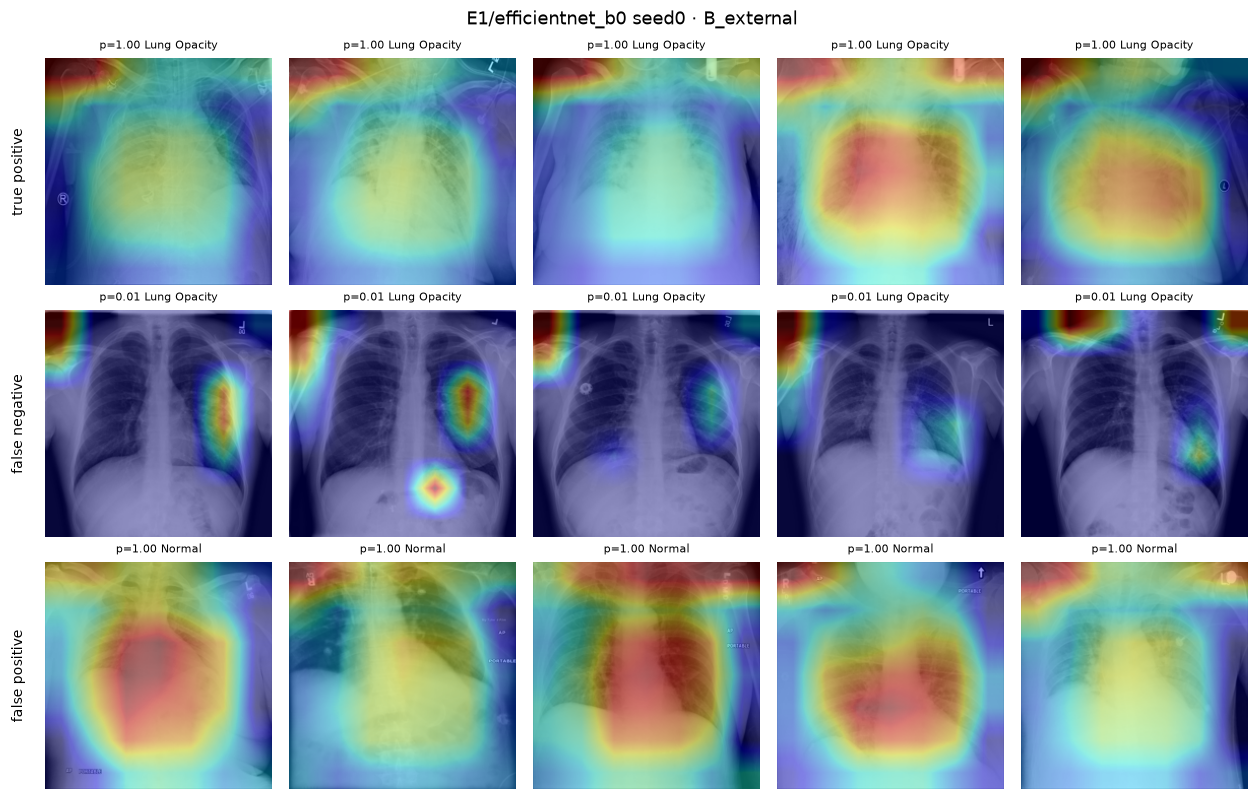

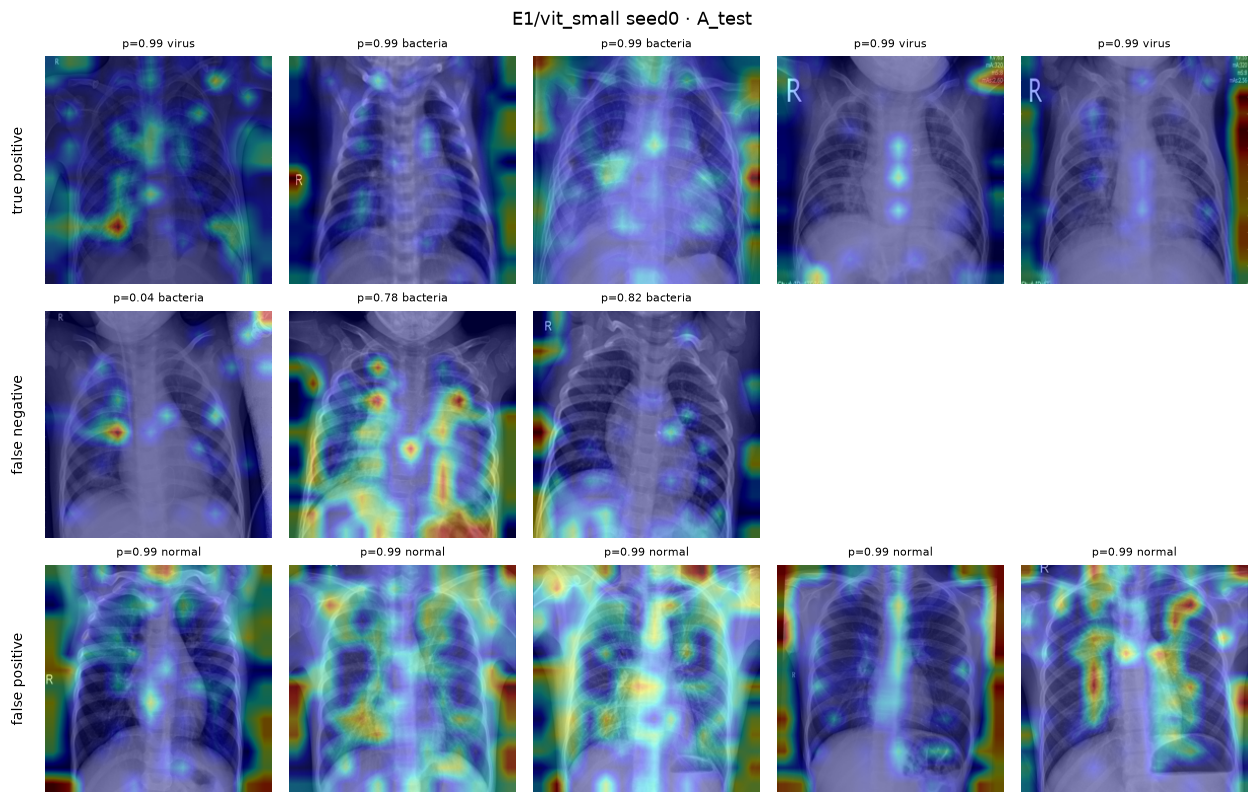

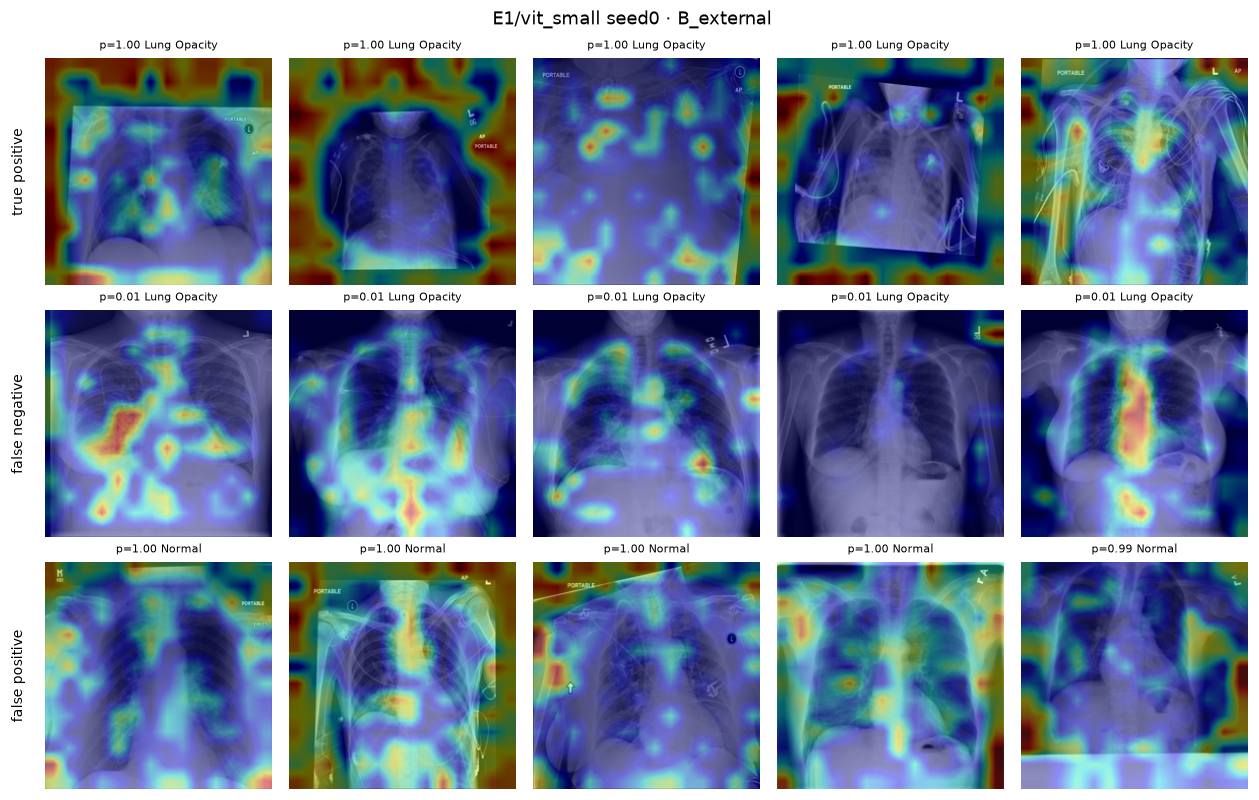

In [7]:
device = get_device()
def cam_gallery(e, a, s, name, manifest, n=5):
    df = preds(e, a, s, name); thr = thr_of(e, a, s)
    col = "label"; df = df[df[col].notna()]
    groups = {"true positive": df[(df[col] == 1) & (df.prob >= thr)].nlargest(n, "prob"),
              "false negative": df[(df[col] == 1) & (df.prob < thr)].nsmallest(n, "prob"),
              "false positive": df[(df[col] == 0) & (df.prob >= thr)].nlargest(n, "prob")}
    imgs, row_of = ensure_cache(manifest, 224, "squash")
    model, _ = load_model(run_path(e, a, s), device)
    fig, axes = plt.subplots(3, n, figsize=(2.3 * n, 7.4))
    for r, (title, g) in enumerate(groups.items()):
        x = torch.from_numpy(np.stack([imgs[row_of[i]] for i in g.image_id])).float().div(255)[:, None].to(device) if len(g) else None
        cams = gradcam(model, x)[0] if x is not None else []
        for c in range(n):
            ax = axes[r, c]; ax.axis("off")
            if c < len(g):
                ax.imshow(overlay(imgs[row_of[g.image_id.iloc[c]]], cams[c]))
                extra = g.iloc[c].get("class3", g.iloc[c].get("orig_label", ""))
                ax.set_title(f"p={g.prob.iloc[c]:.2f} {extra}"[:34], fontsize=7)
        axes[r, 0].text(-20, 112, title, rotation=90, va="center", ha="right", fontsize=9)
    fig.suptitle(f"{e}/{a} seed{s} · {name}"); plt.tight_layout()
    plt.savefig(FIG / f"gradcam_{e}_{a}_{name}.png", bbox_inches="tight"); plt.show()

for (e, a), s in MODELS.items():
    if e == "E1":
        cam_gallery(e, a, s, "A_test", A_MAN)
        cam_gallery(e, a, s, "B_external", B_MAN)

### Quantifying attention outside the lungs
The share of Grad-CAM mass in the outer 15% frame of the image, averaged over 300 random images per test set. A uniform map would put 51% there (that frame is 51% of the area). Values far above that mean the model's evidence comes mostly from the periphery: text markers, collimation edges, shoulders and arms. In a frontal CXR the lungs are mostly inside the central region.

In [8]:
# Where does the attribution mass sit? Share of Grad-CAM mass in the outer 15% border (text markers, collimation edges)
def border_share(e, a, s, name, manifest, n=300):
    df = preds(e, a, s, name).sample(min(n, len(preds(e, a, s, name))), random_state=0)
    imgs, row_of = ensure_cache(manifest, 224, "squash"); model, _ = load_model(run_path(e, a, s), device)
    shares = []
    for i in range(0, len(df), 50):
        ids = df.image_id.iloc[i:i + 50]
        x = torch.from_numpy(np.stack([imgs[row_of[k]] for k in ids])).float().div(255)[:, None].to(device)
        cam = gradcam(model, x)[0]; m = int(224 * 0.15)
        inner = cam[:, m:-m, m:-m].sum(axis=(1, 2)); total = cam.sum(axis=(1, 2)) + 1e-8
        shares.extend(1 - inner / total)
    return float(np.mean(shares))
rows = [{"model": f"{e}/{a}", "set": name, "border_share": border_share(e, a, s, name, man)}
        for (e, a), s in MODELS.items() for name, man in [("A_test", A_MAN), ("B_external", B_MAN)]]
display(pd.DataFrame(rows).round(3))
print("uniform attribution would put", round(1 - (1 - 2 * 0.15) ** 2, 3), "of the mass in the border")

,model,set,border_share
0,E1/efficientnet_b0,A_test,0.409
1,E1/efficientnet_b0,B_external,0.344
2,E2/efficientnet_b0,A_test,0.397
3,E2/efficientnet_b0,B_external,0.401
4,E1/vit_small,A_test,0.601
5,E1/vit_small,B_external,0.512
6,E2/vit_small,A_test,0.527
7,E2/vit_small,B_external,0.465


uniform attribution would put 0.51 of the mass in the border


**Insights (Grad-CAM)**
* **EfficientNet on B: true and false positives look alike.** Both rows are dominated by AP/portable films (the "PORTABLE"/"AP" text markers are visible in several false positives), with diffuse heat over the whole thorax plus the upper image edge (neck, clavicles, collimation). The model responds to a global "sick-patient AP film" appearance more than to a specific opacity.
* **EfficientNet false negatives on B are PA films with *focal* opacities.** The heat map often finds the opacity (a hot spot in the lower or mid zone), yet the score is about 0.01. The model has learned that a clean, upright PA-type image means "normal", which overrides local evidence. Pediatric pneumonia in A is often more diffuse, so focal adult consolidations may simply not look like A's pneumonia.
* **ViT-S on Test A: attention is scattered and peripheral.** It falls on image corners, the borders, the laterality marker and text annotations (top-right corners in several true positives), as well as on the lungs. False positives show heat on edges and corners. This matches its lower AUROC and seed instability.
* **Border share:** EfficientNet keeps 34–41% of attribution mass in the outer frame, *below* the 51% uniform baseline, so it is centrally focused. ViT E1 puts 60% (Test A) / 51% (B) there, and augmentation reduces it to 53% / 47%. Augmentation moves the transformer's evidence towards the lungs, consistent with its larger external gain.
* Caveat: these galleries show the *most confident* cases and are selected, not random. Grad-CAM is coarse, and for ViT it is less faithful than for CNNs.

## Summary of failure modes
1. **AP/portable films → false positives** (normal AP specificity about 0.2–0.25 for E1). This is the largest single error source on B.
2. **Focal adult consolidations on clean PA films → false negatives.**
3. **Non-pneumonia abnormalities → called pneumonia**: the model has no concept of "other disease".
4. **Over-confidence and threshold shift on B**, partly fixable by local recalibration.
5. **Residual association with acquisition properties** in A, not removed by conventional augmentation.

These failure modes define what useful *synthetic* data would need to contain: realistic AP-style normals, focal consolidations and acquisition variety. Merely more images like A's would not help.